<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%207/DS_Practice_SupervisedClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/arafatro/IntroToDS/blob/main/Practice%20Materials/Week%20X/DS_Practice_SupervisedClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Data Science
## Practice Session: Supervised Learning: Classification
**Eötvös Loránd University (ELTE) · Faculty of Informatics**

---
**Instructor:** Arafat Md Easin  
**Goal:** By the end of this session you will be able to:
- Understand the **supervised classification workflow**: split, train, evaluate
- Train and compare **Logistic Regression, KNN, Decision Tree, Random Forest, and SVM**
- Read a **confusion matrix** and choose between accuracy, precision, recall, F1, and ROC-AUC
- Diagnose **underfitting and overfitting** with validation curves
- Tune hyperparameters with **GridSearchCV** and handle **class imbalance**

> **Tip:** Run each cell with `Shift + Enter` and read the comments carefully before moving on.  
> **Key principle:** A model is only as good as the way you evaluate it. A single accuracy number on the wrong split, or on the wrong metric, can hide a model that fails exactly where it matters.

---

## Part 0: Setup & Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import (
    train_test_split, cross_val_score, cross_validate,
    StratifiedKFold, GridSearchCV, validation_curve
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, roc_auc_score, make_scorer
)

# ── Reproducible randomness ───────────────────────────────────────────
RNG = np.random.default_rng(seed=42)

# ── Plot style ────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"]     = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Setup complete.")

Setup complete.


In [ ]:
# ── Load datasets ─────────────────────────────────────────────────────
# We use two classic sklearn datasets:
#   breast_cancer: 30 features, binary target (malignant / benign)
#   wine:          13 features, 3-class target (wine cultivar)

# Breast Cancer dataset
bc = load_breast_cancer()
X_bc = pd.DataFrame(bc.data, columns=bc.feature_names)
y_bc = pd.Series(bc.target, name="target")   # 0 = malignant, 1 = benign

# Wine dataset
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine = pd.Series(wine.target, name="cultivar")

print("=== Breast Cancer ===")
print(f"  Samples: {X_bc.shape[0]},  Features: {X_bc.shape[1]}")
print(f"  Classes: {dict(zip(map(str, bc.target_names), map(int, np.bincount(y_bc))))}")
print()
print("=== Wine ===")
print(f"  Samples: {X_wine.shape[0]},  Features: {X_wine.shape[1]}")
print(f"  Classes: {dict(zip(map(str, wine.target_names), map(int, np.bincount(y_wine))))}")

=== Breast Cancer ===
  Samples: 569,  Features: 30
  Classes: {'malignant': 212, 'benign': 357}

=== Wine ===
  Samples: 178,  Features: 13
  Classes: {'class_0': 59, 'class_1': 71, 'class_2': 48}


---
## Part 1: The Classification Workflow

**Supervised classification** learns a mapping from features $X$ to a **discrete label** $y$ using examples where the correct label is already known.

The standard workflow has five steps:

| Step | What you do | Why |
|---|---|---|
| **1. Split** | Hold out a test set before doing anything else | The test set must simulate *unseen* data |
| **2. Baseline** | Fit a trivial model (always predict the majority class) | Gives you a floor: any real model must beat it |
| **3. Train** | Fit candidate models on the training set only | Learn patterns from labelled examples |
| **4. Evaluate** | Score with cross-validation, then once on the test set | Estimate real-world performance honestly |
| **5. Tune** | Adjust hyperparameters using CV, never the test set | Improve without leaking test information |

> **Stratified split:** When classes are not equally frequent, use `stratify=y` so that train and test keep the same class proportions.  
> **Critical rule:** The test set is used **once**, at the very end. If you keep peeking at it to choose models, it stops being a test set.

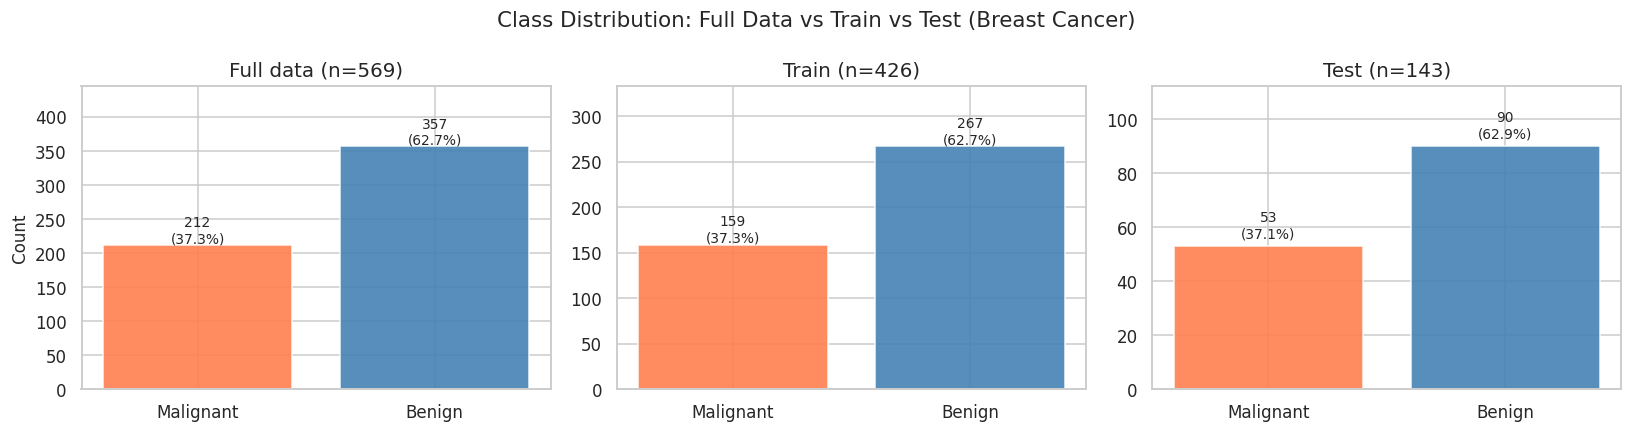

Train: 426 samples   Test: 143 samples
Stratification keeps the malignant/benign ratio almost identical in all three sets.


In [ ]:
# ── 1.1  Class balance and the stratified train/test split ───────────
# Always look at the class distribution before modelling.

X_train, X_test, y_train, y_test = train_test_split(
    X_bc, y_bc, test_size=0.25, stratify=y_bc, random_state=42
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Class Distribution: Full Data vs Train vs Test (Breast Cancer)", fontsize=14)

for ax, (name, y) in zip(axes, [("Full data", y_bc), ("Train", y_train), ("Test", y_test)]):
    counts = y.map({0: "Malignant", 1: "Benign"}).value_counts()[["Malignant", "Benign"]]
    ax.bar(counts.index, counts.values, color=["coral", "steelblue"], edgecolor="white", alpha=0.9)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 3, f"{v}\n({v / len(y) * 100:.1f}%)", ha="center", fontsize=9)
    ax.set_title(f"{name} (n={len(y)})")
    ax.set_ylim(0, counts.max() * 1.25)
    ax.set_ylabel("Count" if ax == axes[0] else "")

plt.tight_layout()
plt.show()

print(f"Train: {X_train.shape[0]} samples   Test: {X_test.shape[0]} samples")
print("Stratification keeps the malignant/benign ratio almost identical in all three sets.")

In [ ]:
# ── 1.2  The baseline: always predict the majority class ─────────────
# A model that ignores all features and predicts "benign" every time.
# Any serious model must beat this floor.

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print(f"Baseline accuracy:            {accuracy_score(y_test, dummy_pred):.4f}")
print(f"Baseline recall (malignant):  {recall_score(y_test, dummy_pred, pos_label=0):.4f}")
print()
print("The baseline looks decent on accuracy, yet it never detects a single malignant tumour.")
print("This is why accuracy alone can be dangerously misleading. More on this in Part 3.")

Baseline accuracy:            0.6294
Baseline recall (malignant):  0.0000

The baseline looks decent on accuracy, yet it never detects a single malignant tumour.
This is why accuracy alone can be dangerously misleading. More on this in Part 3.


---
## Part 2: Classification Models

Different models make different assumptions about the shape of the decision boundary.

| Model | Idea | Needs scaling? | Strength | Weakness |
|---|---|---|---|---|
| **Logistic Regression** | Linear boundary, outputs probabilities | Yes | Fast, interpretable | Cannot bend around non-linear classes |
| **KNN** | Vote of the $k$ nearest training points | **Yes** (distance-based) | No training, flexible | Slow at prediction, hurt by irrelevant features |
| **Decision Tree** | Sequence of if/else splits | No | Interpretable, handles any scale | Overfits easily when deep |
| **Random Forest** | Many trees, majority vote | No | Strong default, robust | Less interpretable, larger model |
| **SVM (RBF)** | Maximum-margin boundary in a transformed space | **Yes** | Powerful on small/medium data | Slow on very large data, needs tuning |

> **Rule of thumb:** Put a `StandardScaler` inside the pipeline for every distance- or gradient-based model (Logistic Regression, KNN, SVM). Trees do not need it.

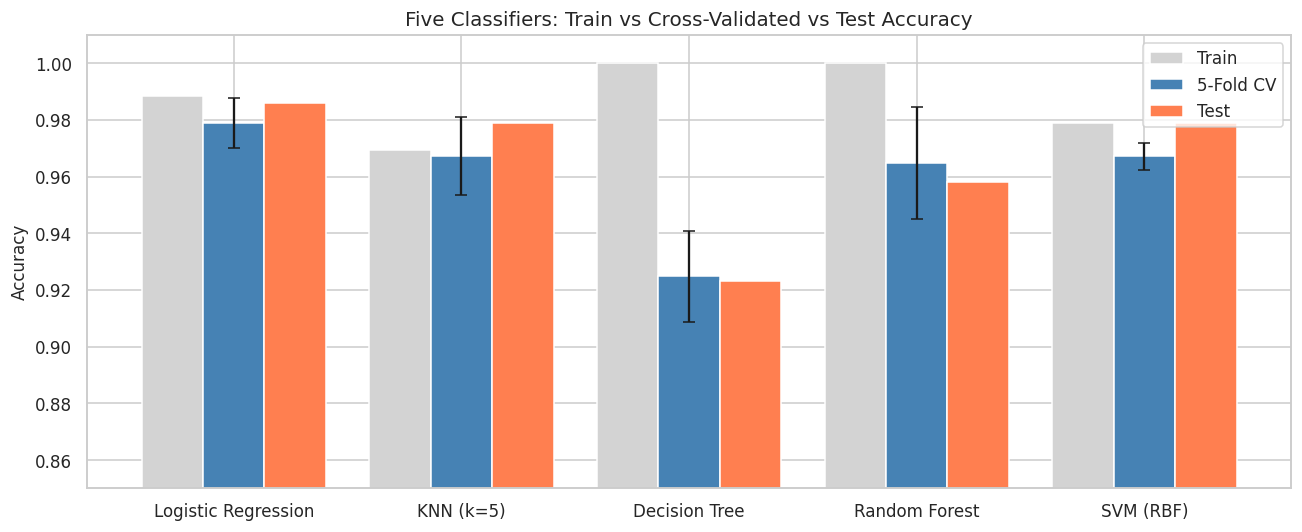

                     train_acc  cv_acc  cv_std  test_acc
model                                                   
Logistic Regression     0.9883  0.9789  0.0088    0.9860
KNN (k=5)               0.9695  0.9671  0.0138    0.9790
Decision Tree           1.0000  0.9248  0.0161    0.9231
Random Forest           1.0000  0.9648  0.0196    0.9580
SVM (RBF)               0.9789  0.9671  0.0047    0.9790

Train accuracy of 1.000 for Decision Tree and Random Forest means they memorised the training set.
Compare the Train bar to the CV bar: a large gap is the first symptom of overfitting.


In [ ]:
# ── 2.1  Train five models and compare ───────────────────────────────
# Scaling lives inside each Pipeline so it is fit on training data only.

models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=5000, random_state=42))]),
    "KNN (k=5)":           Pipeline([("scaler", StandardScaler()),
                                     ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "Decision Tree":       Pipeline([("clf", DecisionTreeClassifier(random_state=42))]),
    "Random Forest":       Pipeline([("clf", RandomForestClassifier(n_estimators=200, random_state=42))]),
    "SVM (RBF)":           Pipeline([("scaler", StandardScaler()),
                                     ("clf", SVC(probability=True, random_state=42))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, pipe in models.items():
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    pipe.fit(X_train, y_train)
    rows.append({
        "model":     name,
        "train_acc": pipe.score(X_train, y_train),
        "cv_acc":    cv_scores.mean(),
        "cv_std":    cv_scores.std(),
        "test_acc":  pipe.score(X_test, y_test),
    })

results_df = pd.DataFrame(rows).set_index("model")

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(results_df))
width = 0.27
ax.bar(x - width, results_df["train_acc"], width, label="Train",        color="lightgrey", edgecolor="white")
ax.bar(x,         results_df["cv_acc"],    width, yerr=results_df["cv_std"], capsize=4,
       label="5-Fold CV",   color="steelblue", edgecolor="white")
ax.bar(x + width, results_df["test_acc"],  width, label="Test",         color="coral", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(results_df.index)
ax.set_ylim(0.85, 1.01)
ax.set_ylabel("Accuracy")
ax.set_title("Five Classifiers: Train vs Cross-Validated vs Test Accuracy")
ax.legend()
plt.tight_layout()
plt.show()

print(results_df.round(4).to_string())
print("\nTrain accuracy of 1.000 for Decision Tree and Random Forest means they memorised the training set.")
print("Compare the Train bar to the CV bar: a large gap is the first symptom of overfitting.")

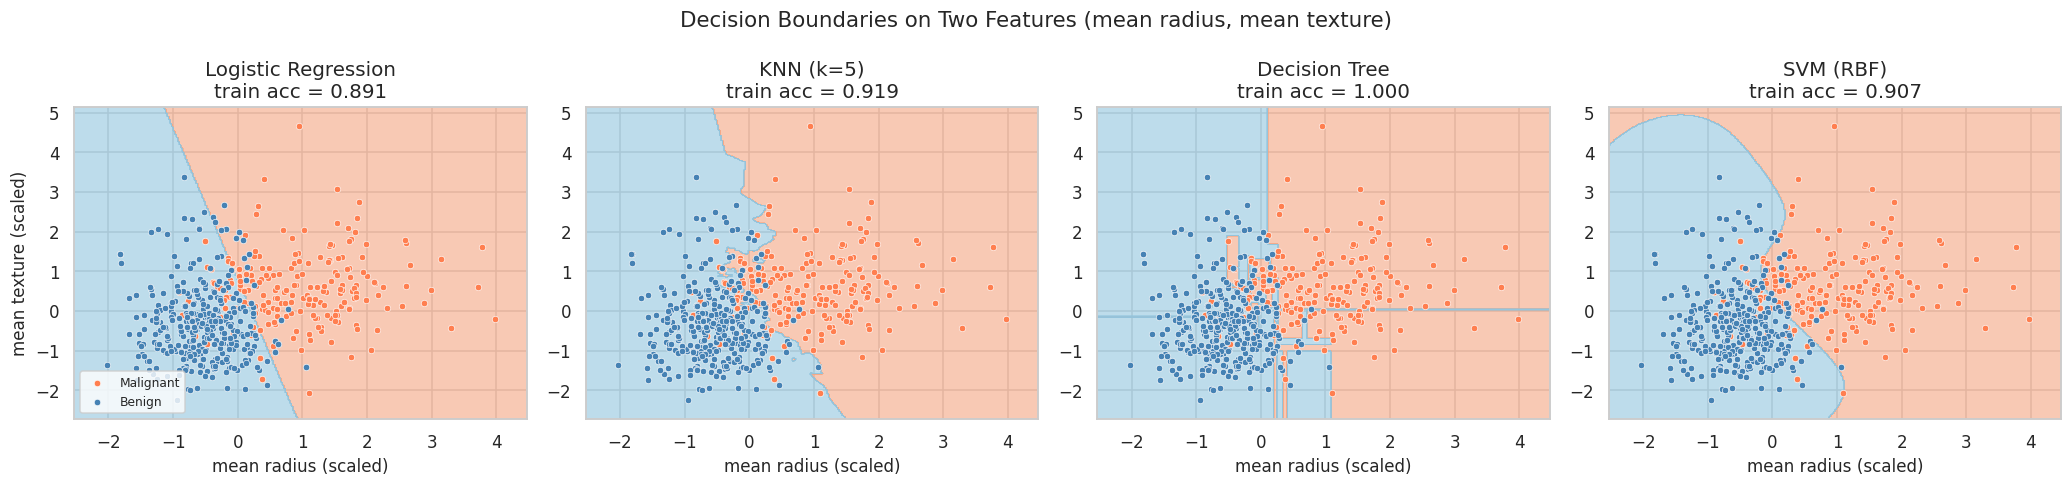

Logistic Regression: straight line.  KNN and Tree: jagged, follow individual points.
SVM (RBF): smooth curve.  The more flexible the boundary, the higher the risk of overfitting.


In [ ]:
# ── 2.2  Decision boundaries: how each model carves up the space ─────
# We train on just two features so we can SEE the boundary.
# (This is for illustration only. Real models use all features.)

two = ["mean radius", "mean texture"]
X2 = StandardScaler().fit_transform(X_bc[two])
y2 = y_bc.values

demo_models = {
    "Logistic Regression": LogisticRegression(),
    "KNN (k=5)":           KNeighborsClassifier(n_neighbors=5),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "SVM (RBF)":           SVC(random_state=42),
}

xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5, 300),
                     np.linspace(X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5, 300))
bg = ListedColormap(["#f4a582", "#92c5de"])

fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))
fig.suptitle("Decision Boundaries on Two Features (mean radius, mean texture)", fontsize=14)

for ax, (name, m) in zip(axes, demo_models.items()):
    m.fit(X2, y2)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=bg, alpha=0.6)
    ax.scatter(X2[y2 == 0, 0], X2[y2 == 0, 1], c="coral",     s=18, edgecolors="white", linewidth=0.4, label="Malignant")
    ax.scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], c="steelblue", s=18, edgecolors="white", linewidth=0.4, label="Benign")
    ax.set_title(f"{name}\ntrain acc = {m.score(X2, y2):.3f}")
    ax.set_xlabel("mean radius (scaled)")
    ax.set_ylabel("mean texture (scaled)" if ax == axes[0] else "")
axes[0].legend(fontsize=8, loc="lower left")

plt.tight_layout()
plt.show()

print("Logistic Regression: straight line.  KNN and Tree: jagged, follow individual points.")
print("SVM (RBF): smooth curve.  The more flexible the boundary, the higher the risk of overfitting.")

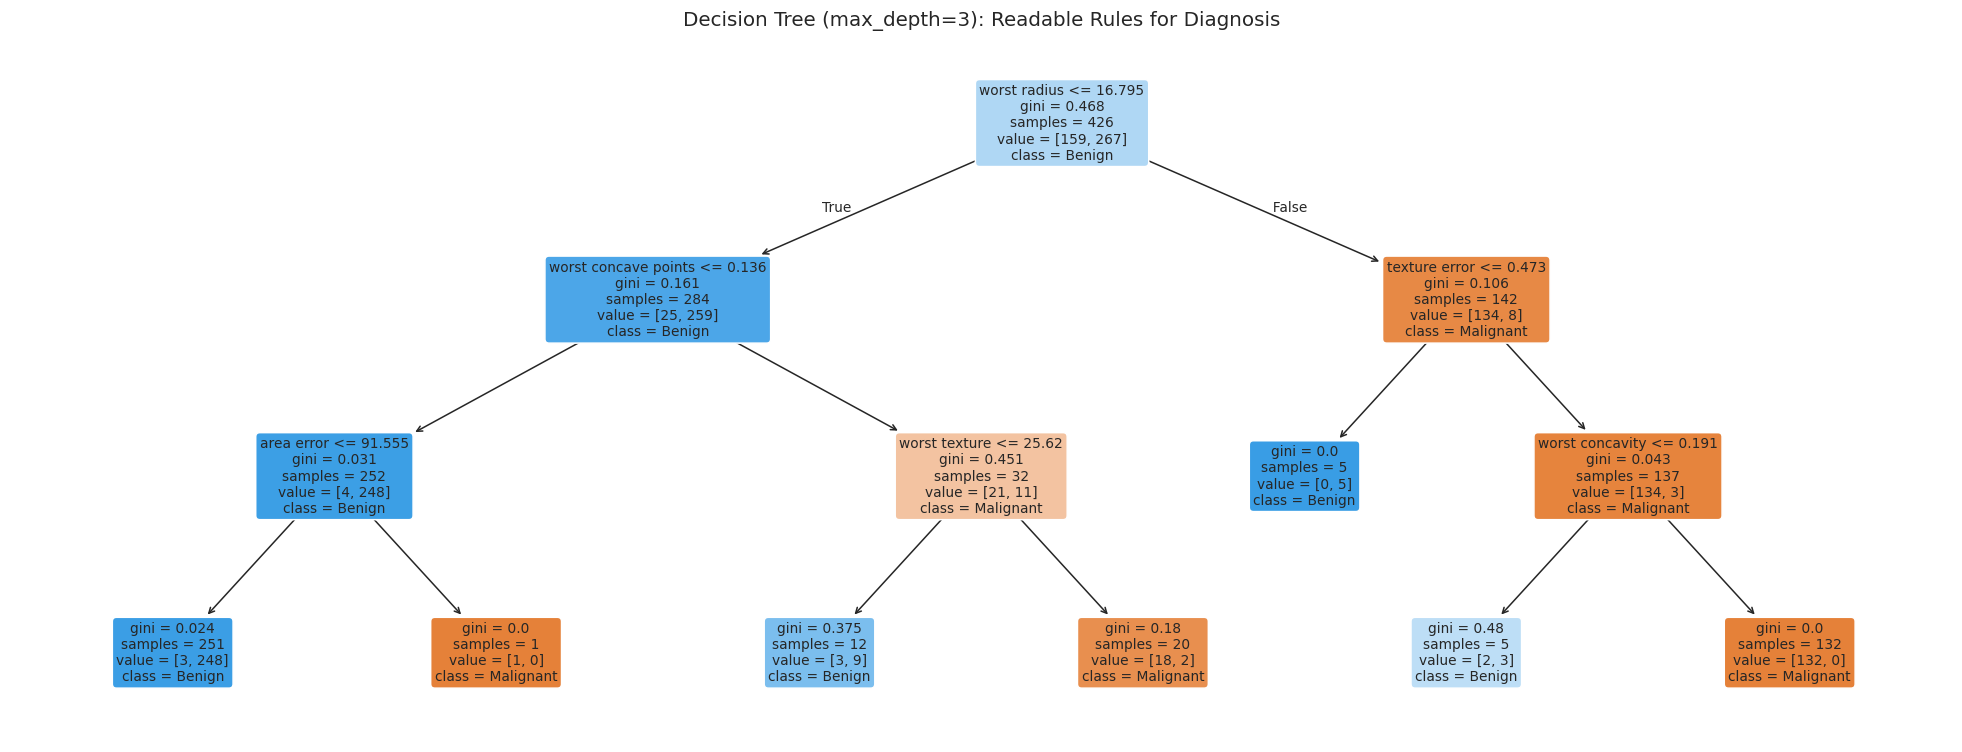

Depth-3 tree accuracy on test set: 0.9441
Each box shows the split rule, the Gini impurity, the samples reaching that node, and the majority class.


In [ ]:
# ── 2.3  Open the black box: a shallow decision tree ─────────────────
# Trees are the most interpretable classifier: you can read the rules.

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(tree, feature_names=X_bc.columns, class_names=["Malignant", "Benign"],
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Decision Tree (max_depth=3): Readable Rules for Diagnosis", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Depth-3 tree accuracy on test set: {tree.score(X_test, y_test):.4f}")
print("Each box shows the split rule, the Gini impurity, the samples reaching that node, and the majority class.")

### Exercise 1

Using the **Wine dataset** (`X_wine`, `y_wine`):

1. Split into train (75%) and test (25%) with `stratify=y_wine` and `random_state=42`.
2. Build the same **five models** as in 2.1 (scale inside the pipeline where needed).
3. Evaluate each with 5-fold stratified CV on the training set and once on the test set.
4. Plot **Train / CV / Test** accuracy as a grouped bar chart.
5. Which model is best? Is there a clear case of overfitting? Does the wine data separate more easily than the breast cancer data?

```python
# Your code here
```

```
# Your answer here
```

---
## Part 3: Evaluation Metrics

Accuracy answers *"how often is the model right?"* but not *"what kind of mistakes does it make?"*. The **confusion matrix** breaks the answer down.

For a binary problem, choose one class as **positive**. Here we treat **malignant** as positive, because missing a cancer is the costly mistake.

| | Predicted Positive | Predicted Negative |
|---|---|---|
| **Actually Positive** | True Positive (TP) | False Negative (FN): *missed cancer* |
| **Actually Negative** | False Positive (FP): *false alarm* | True Negative (TN) |

| Metric | Formula | Answers the question |
|---|---|---|
| **Accuracy** | $(TP + TN) / N$ | How often is the model right overall? |
| **Precision** | $TP / (TP + FP)$ | Of the cases flagged positive, how many really are? |
| **Recall** | $TP / (TP + FN)$ | Of all real positives, how many did we catch? |
| **F1** | $2PR / (P + R)$ | Harmonic mean of precision and recall |
| **ROC-AUC** | Area under TPR vs FPR curve | How well does the model *rank* positives above negatives, at any threshold? |

> **Precision vs recall is a trade-off.** Flag everything and recall is perfect but precision collapses. Flag almost nothing and precision looks great but recall collapses. The right balance depends on the **cost of each error**.

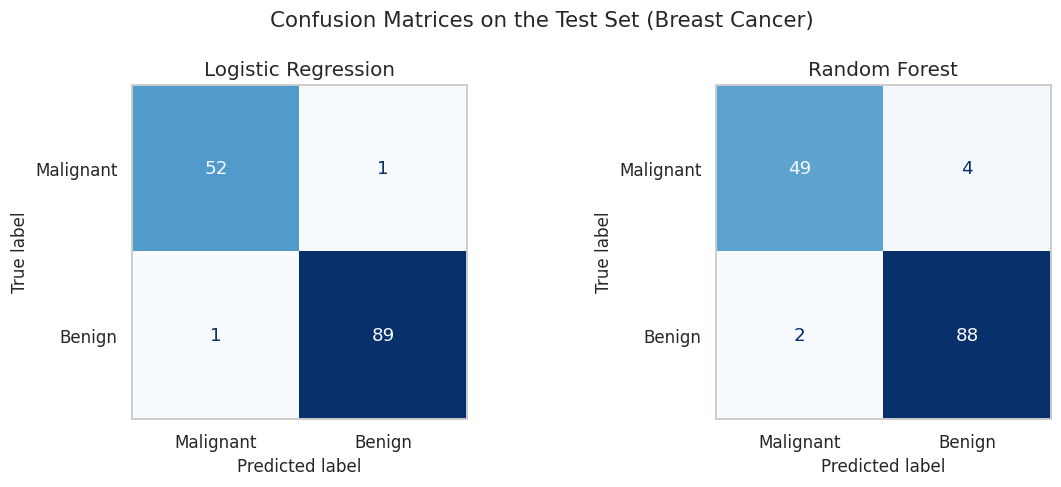

Logistic Regression   TP=52  FN=1 (missed cancers)  FP=1 (false alarms)  TN=89
Random Forest         TP=49  FN=4 (missed cancers)  FP=2 (false alarms)  TN=88


In [ ]:
# ── 3.1  Confusion matrix for the best two models ────────────────────
# Display labels: index 0 = Malignant, index 1 = Benign.

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle("Confusion Matrices on the Test Set (Breast Cancer)", fontsize=14)

for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    pred = models[name].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Malignant", "Benign"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)

plt.tight_layout()
plt.show()

for name in ["Logistic Regression", "Random Forest"]:
    pred = models[name].predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])   # rows = actual, cols = predicted (0 first)
    TP, FN, FP, TN = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
    print(f"{name:20s}  TP={TP}  FN={FN} (missed cancers)  FP={FP} (false alarms)  TN={TN}")

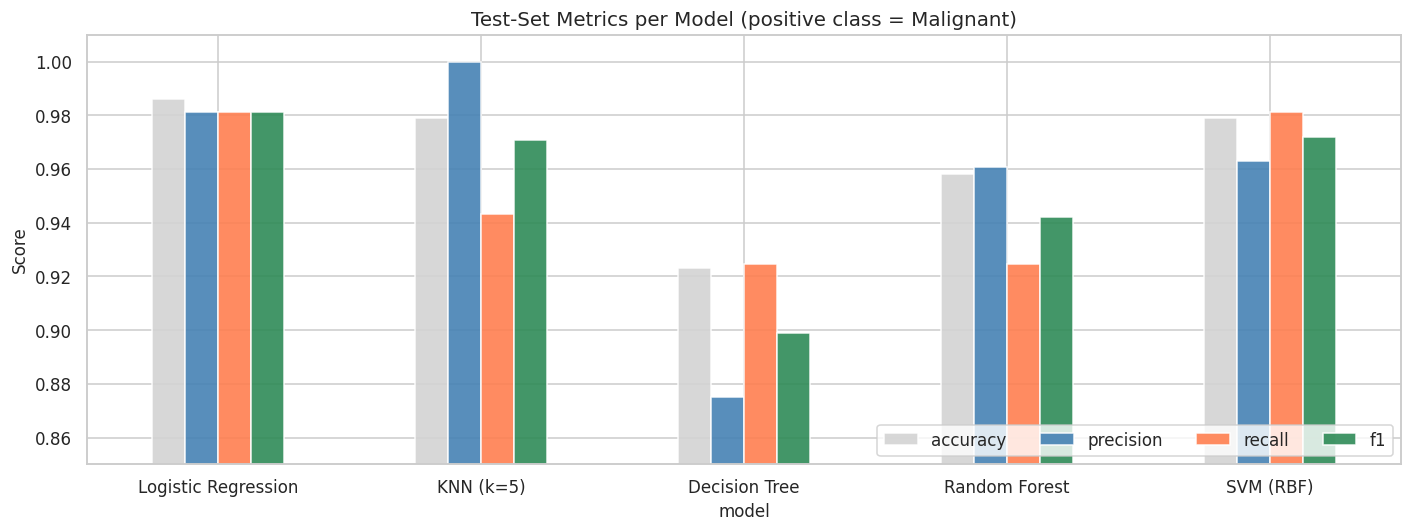

                     accuracy  precision  recall      f1
model                                                   
Logistic Regression    0.9860     0.9811  0.9811  0.9811
KNN (k=5)              0.9790     1.0000  0.9434  0.9709
Decision Tree          0.9231     0.8750  0.9245  0.8991
Random Forest          0.9580     0.9608  0.9245  0.9423
SVM (RBF)              0.9790     0.9630  0.9811  0.9720

Full per-class report for Logistic Regression:
              precision    recall  f1-score   support

   Malignant      0.981     0.981     0.981        53
      Benign      0.989     0.989     0.989        90

    accuracy                          0.986       143
   macro avg      0.985     0.985     0.985       143
weighted avg      0.986     0.986     0.986       143



In [ ]:
# ── 3.2  Precision, recall, F1 for the malignant class ───────────────

metric_rows = []
for name, pipe in models.items():
    pred = pipe.predict(X_test)
    metric_rows.append({
        "model":     name,
        "accuracy":  accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, pos_label=0),
        "recall":    recall_score(y_test, pred, pos_label=0),
        "f1":        f1_score(y_test, pred, pos_label=0),
    })
metric_df = pd.DataFrame(metric_rows).set_index("model")

fig, ax = plt.subplots(figsize=(13, 5))
metric_df.plot(kind="bar", ax=ax, edgecolor="white", alpha=0.9,
               color=["lightgrey", "steelblue", "coral", "seagreen"])
ax.set_ylim(0.85, 1.01)
ax.set_ylabel("Score")
ax.set_title("Test-Set Metrics per Model (positive class = Malignant)")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right", ncol=4)
plt.tight_layout()
plt.show()

print(metric_df.round(4).to_string())
print()
print("Full per-class report for Logistic Regression:")
print(classification_report(y_test, models["Logistic Regression"].predict(X_test),
                            target_names=["Malignant", "Benign"], digits=3))

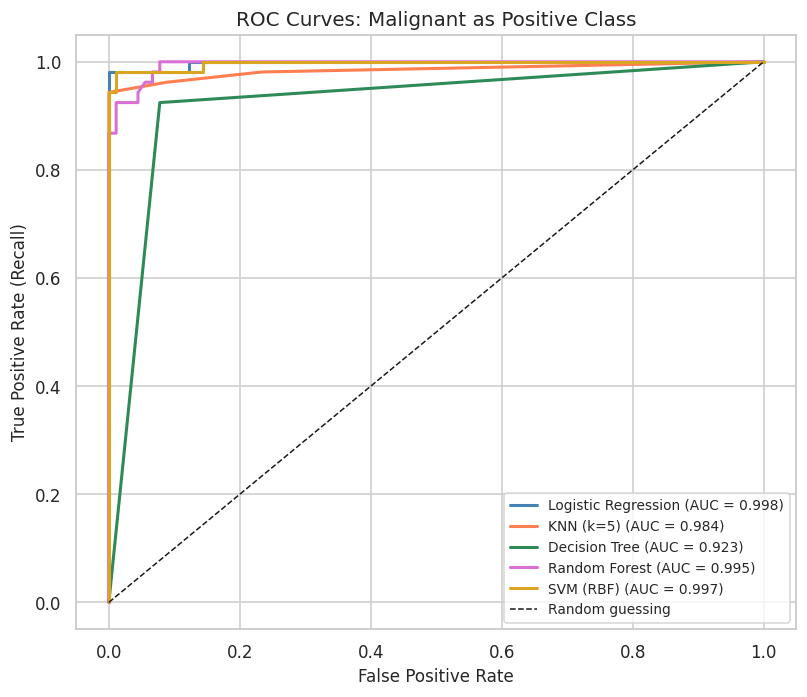

A curve hugging the top-left corner is best. The single decision tree is visibly weaker than the rest.


In [ ]:
# ── 3.3  ROC curves: threshold-free comparison ───────────────────────
# Each classifier outputs a probability. Sweeping the decision threshold from 0 to 1
# traces a curve of True Positive Rate vs False Positive Rate.
# AUC = 1.0 is perfect ranking, AUC = 0.5 is random guessing.

y_mal = (y_test == 0).astype(int)     # 1 = malignant (positive class)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
palette = ["steelblue", "coral", "seagreen", "orchid", "goldenrod"]

for (name, pipe), color in zip(models.items(), palette):
    p_mal = pipe.predict_proba(X_test)[:, 0]          # column 0 = P(malignant)
    fpr, tpr, _ = roc_curve(y_mal, p_mal)
    auc = roc_auc_score(y_mal, p_mal)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guessing")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_title("ROC Curves: Malignant as Positive Class")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

print("A curve hugging the top-left corner is best. The single decision tree is visibly weaker than the rest.")

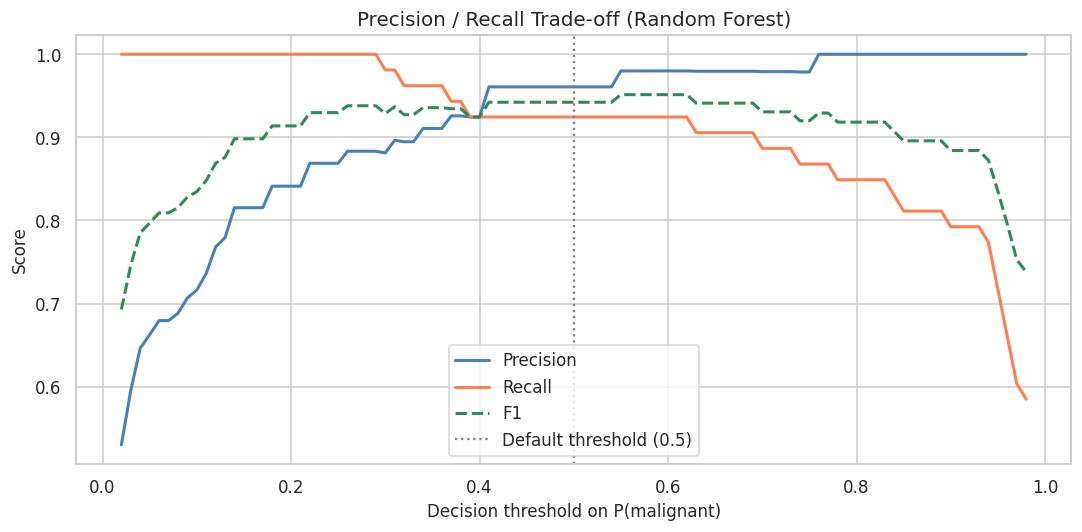

Confusion counts at three thresholds:
  threshold = 0.5:  missed cancers (FN) = 4,  false alarms (FP) = 2
  threshold = 0.3:  missed cancers (FN) = 0,  false alarms (FP) = 7
  threshold = 0.2:  missed cancers (FN) = 0,  false alarms (FP) = 10


In [ ]:
# ── 3.4  The decision threshold is a dial, not a constant ────────────
# By default we predict "malignant" when P(malignant) >= 0.5.
# We use the Random Forest here because it missed the most cancers at the default threshold.
# Lowering the threshold catches more cancers (higher recall) at the cost of more false alarms.

rf_pipe = models["Random Forest"]
p_mal   = rf_pipe.predict_proba(X_test)[:, 0]

thresholds = np.linspace(0.02, 0.98, 97)
prec, rec, f1s = [], [], []
for t in thresholds:
    pred = (p_mal >= t).astype(int)
    prec.append(precision_score(y_mal, pred, zero_division=0))
    rec.append(recall_score(y_mal, pred))
    f1s.append(f1_score(y_mal, pred, zero_division=0))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, prec, color="steelblue", linewidth=2, label="Precision")
ax.plot(thresholds, rec,  color="coral",     linewidth=2, label="Recall")
ax.plot(thresholds, f1s,  color="seagreen",  linewidth=2, linestyle="--", label="F1")
ax.axvline(0.5, color="grey", linestyle=":", linewidth=1.5, label="Default threshold (0.5)")
ax.set_xlabel("Decision threshold on P(malignant)")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall Trade-off (Random Forest)")
ax.legend()
plt.tight_layout()
plt.show()

print("Confusion counts at three thresholds:")
for t in [0.5, 0.3, 0.2]:
    pred = (p_mal >= t).astype(int)
    FN = int(((y_mal == 1) & (pred == 0)).sum())
    FP = int(((y_mal == 0) & (pred == 1)).sum())
    print(f"  threshold = {t}:  missed cancers (FN) = {FN},  false alarms (FP) = {FP}")

### Exercise 2

Using the **Wine dataset** with the models you trained in Exercise 1:

1. Plot the **3 × 3 confusion matrix** of the best model on the test set (use `ConfusionMatrixDisplay` with the cultivar names).
2. Print a `classification_report` with per-class precision, recall, and F1.
3. Which cultivar is most often confused with which other? Quote the numbers from the matrix.
4. Compute the **macro-averaged F1** and the **one-vs-rest ROC-AUC** (`roc_auc_score(y_test, proba, multi_class="ovr")`).
5. Write one sentence on why a multi-class problem needs per-class metrics and not just overall accuracy.

```python
# Your code here
```

```
# Your answer here
```

---
## Part 4: Underfitting, Overfitting & Validation Curves

Every model has **complexity knobs** (tree depth, number of neighbours, regularisation strength).

| Regime | Complexity | Train score | Validation score | Diagnosis |
|---|---|---|---|---|
| **Underfitting** | Too low | Low | Low | The model is too simple to capture the pattern (high bias) |
| **Good fit** | Just right | High | High, close to train | The model generalises |
| **Overfitting** | Too high | Very high | Noticeably lower | The model memorised noise (high variance) |

A **validation curve** sweeps one hyperparameter and plots train vs cross-validated score. The best setting is where the validation score peaks, not where the train score peaks.

> **Bias-variance trade-off:** simple models have high bias and low variance; flexible models have low bias and high variance. Your job is to find the sweet spot.

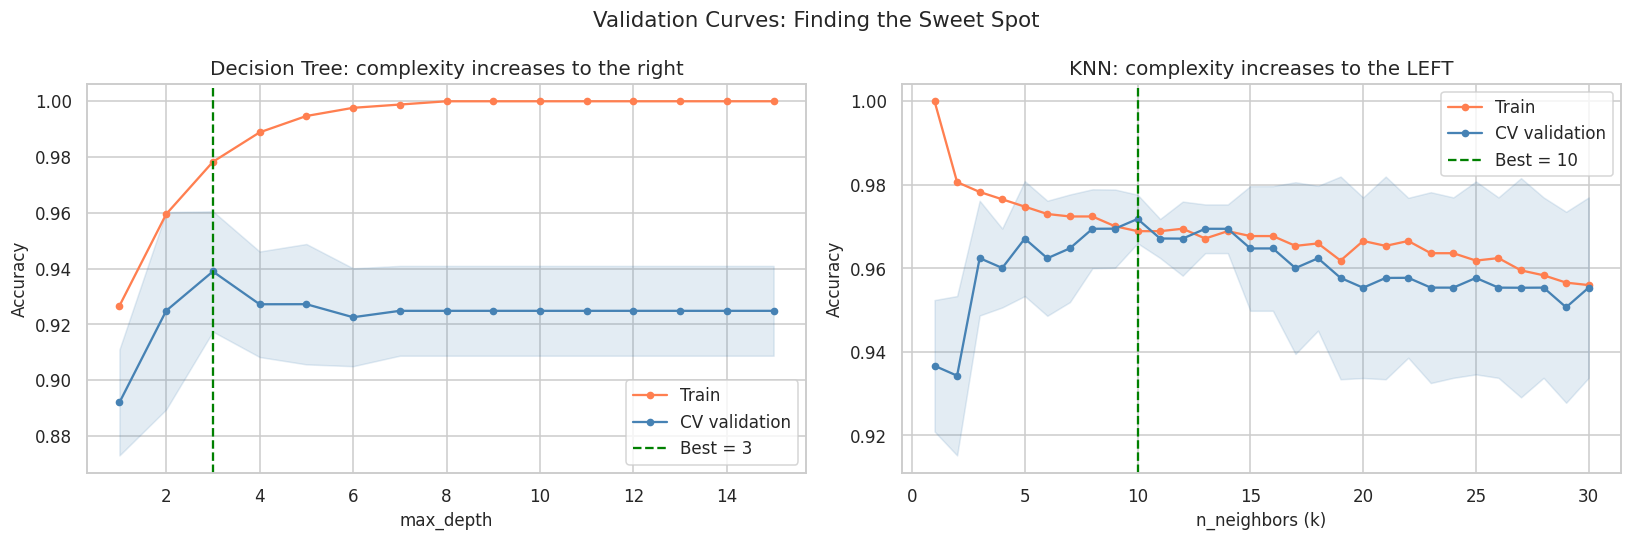

Best tree depth: 3   (CV acc = 0.9390)
Best k for KNN:  10   (CV acc = 0.9718)

Note how the tree's train accuracy keeps climbing to 1.0 while validation accuracy stalls or drops: that gap is overfitting.


In [ ]:
# ── 4.1  Validation curves: tree depth and KNN neighbours ────────────

depths = np.arange(1, 16)
tr_d, va_d = validation_curve(
    DecisionTreeClassifier(random_state=42), X_train, y_train,
    param_name="max_depth", param_range=depths, cv=cv, scoring="accuracy")

ks = np.arange(1, 31)
knn_pipe = Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())])
tr_k, va_k = validation_curve(
    knn_pipe, X_train, y_train,
    param_name="clf__n_neighbors", param_range=ks, cv=cv, scoring="accuracy")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Validation Curves: Finding the Sweet Spot", fontsize=14)

for ax, rng_, tr, va, xlabel, title in [
        (axes[0], depths, tr_d, va_d, "max_depth", "Decision Tree: complexity increases to the right"),
        (axes[1], ks,     tr_k, va_k, "n_neighbors (k)", "KNN: complexity increases to the LEFT")]:
    ax.plot(rng_, tr.mean(axis=1), "o-", color="coral", label="Train", markersize=4)
    ax.plot(rng_, va.mean(axis=1), "o-", color="steelblue", label="CV validation", markersize=4)
    ax.fill_between(rng_, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1),
                    color="steelblue", alpha=0.15)
    best = rng_[np.argmax(va.mean(axis=1))]
    ax.axvline(best, color="green", linestyle="--", linewidth=1.5, label=f"Best = {best}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Accuracy")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

print(f"Best tree depth: {depths[np.argmax(va_d.mean(axis=1))]}   "
      f"(CV acc = {va_d.mean(axis=1).max():.4f})")
print(f"Best k for KNN:  {ks[np.argmax(va_k.mean(axis=1))]}   "
      f"(CV acc = {va_k.mean(axis=1).max():.4f})")
print("\nNote how the tree's train accuracy keeps climbing to 1.0 while validation accuracy stalls or drops: that gap is overfitting.")

### Exercise 3

Using the **Wine dataset** (train split from Exercise 1):

1. Build a pipeline `StandardScaler` + `SVC(kernel="rbf")`.
2. Plot a **validation curve** for the regularisation parameter `C` using `np.logspace(-3, 3, 13)` and a log-scaled x-axis. Show train and CV accuracy.
3. Mark the best `C`.
4. Identify the **underfitting** region and the **overfitting** region on your plot. Which side of the curve is which, and why?

```python
# Your code here
```

```
# Your answer here
```

---
## Part 5: Hyperparameter Tuning with GridSearchCV

Instead of picking hyperparameters by hand, **grid search** tries every combination in a grid, scores each with cross-validation, and keeps the best.

Steps:
1. Put the model in a `Pipeline` (so scaling is refit inside every fold).
2. Define a parameter grid. Parameters of pipeline steps use the `step__param` syntax.
3. Run `GridSearchCV` on the **training set only**.
4. Evaluate the winning model **once** on the test set.

> **Cost warning:** a grid of 6 × 6 values with 5-fold CV means $6 \times 6 \times 5 = 180$ model fits. For large grids use `RandomizedSearchCV`, which samples a fixed number of combinations.

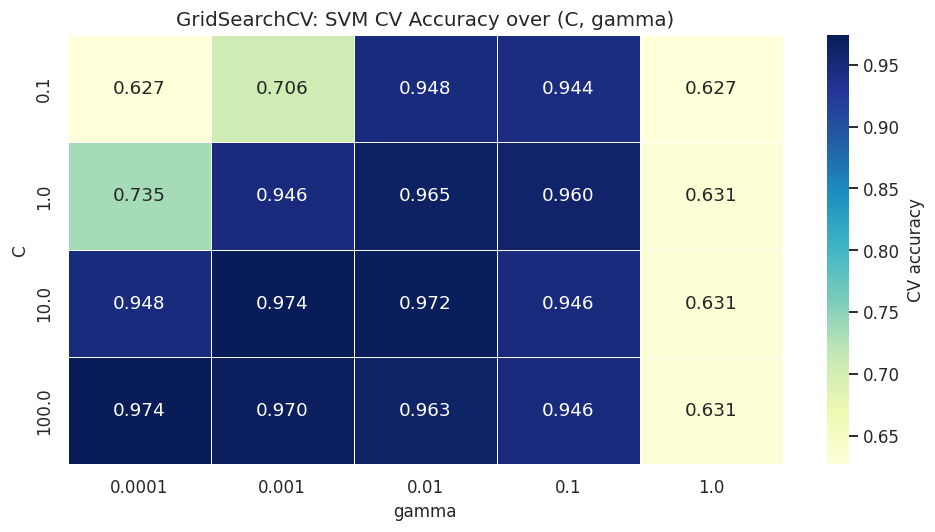

Best parameters: {'clf__C': 10, 'clf__gamma': 0.001}
Best CV accuracy: 0.9742

The top-left (small C, small gamma) underfits; the bottom-right (large C, large gamma) overfits.


In [ ]:
# ── 5.1  Grid search for an SVM ──────────────────────────────────────
# C: how strictly the model avoids training errors (large C = more flexible boundary).
# gamma: reach of a single training point (large gamma = very local, wiggly boundary).

svm_pipe = Pipeline([("scaler", StandardScaler()), ("clf", SVC(random_state=42))])

param_grid = {
    "clf__C":     [0.1, 1, 10, 100],
    "clf__gamma": [0.0001, 0.001, 0.01, 0.1, 1],
}

grid = GridSearchCV(svm_pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

scores = pd.DataFrame(grid.cv_results_)
heat = scores.pivot(index="param_clf__C", columns="param_clf__gamma", values="mean_test_score").astype(float)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu", linewidths=0.5, ax=ax,
            cbar_kws={"label": "CV accuracy"})
ax.set_title("GridSearchCV: SVM CV Accuracy over (C, gamma)")
ax.set_xlabel("gamma")
ax.set_ylabel("C")
plt.tight_layout()
plt.show()

print(f"Best parameters: {grid.best_params_}")
print(f"Best CV accuracy: {grid.best_score_:.4f}")
print("\nThe top-left (small C, small gamma) underfits; the bottom-right (large C, large gamma) overfits.")

In [ ]:
# ── 5.2  The one-time test-set evaluation ────────────────────────────
# Compare the default SVM with the tuned one on the held-out test set.

default_svm = Pipeline([("scaler", StandardScaler()), ("clf", SVC(random_state=42))]).fit(X_train, y_train)
tuned_svm   = grid.best_estimator_

for name, m in [("Default SVM", default_svm), ("Tuned SVM", tuned_svm)]:
    pred = m.predict(X_test)
    print(f"{name:12s}  accuracy = {accuracy_score(y_test, pred):.4f}   "
          f"recall (malignant) = {recall_score(y_test, pred, pos_label=0):.4f}   "
          f"F1 (malignant) = {f1_score(y_test, pred, pos_label=0):.4f}")

print("\nOn 143 test samples, one patient moves recall by about 2 points. Differences this small are noise,")
print("so judge a tuning gain against the CV standard deviation, not against a single test number.")

Default SVM   accuracy = 0.9790   recall (malignant) = 0.9811   F1 (malignant) = 0.9720
Tuned SVM     accuracy = 0.9790   recall (malignant) = 0.9623   F1 (malignant) = 0.9714

On 143 test samples, one patient moves recall by about 2 points. Differences this small are noise,
so judge a tuning gain against the CV standard deviation, not against a single test number.


### Exercise 4

Using the **Wine dataset** (train/test split from Exercise 1):

1. Build a pipeline `StandardScaler` + `KNeighborsClassifier`.
2. Define a grid over `n_neighbors` (odd values from 1 to 21), `weights` (`"uniform"`, `"distance"`) and `p` (1 for Manhattan, 2 for Euclidean).
3. Run `GridSearchCV` with 5-fold stratified CV on the **training set only**.
4. Print the best parameters and CV score, then evaluate the tuned model **once** on the test set.
5. Compare against default KNN (`k=5`). Is the improvement larger than one CV standard deviation?

```python
# Your code here
```

```
# Your answer here
```

---
## Part 6: Class Imbalance

In many real problems (fraud, disease, defects) the interesting class is **rare**. A model can reach 95% accuracy by never predicting it.

Three practical remedies:

| Remedy | How | Where |
|---|---|---|
| **Better metric** | Use recall, F1, or PR-AUC instead of accuracy | Evaluation |
| **Class weights** | Penalise mistakes on the rare class more heavily | `class_weight="balanced"` |
| **Resampling** | Oversample the rare class or undersample the common one | e.g. `imbalanced-learn` (SMOTE) |

Below we **artificially** make malignant cases rare (about 9%) to see the effect.

Imbalanced set: 392 samples, malignant = 35 (8.9%)


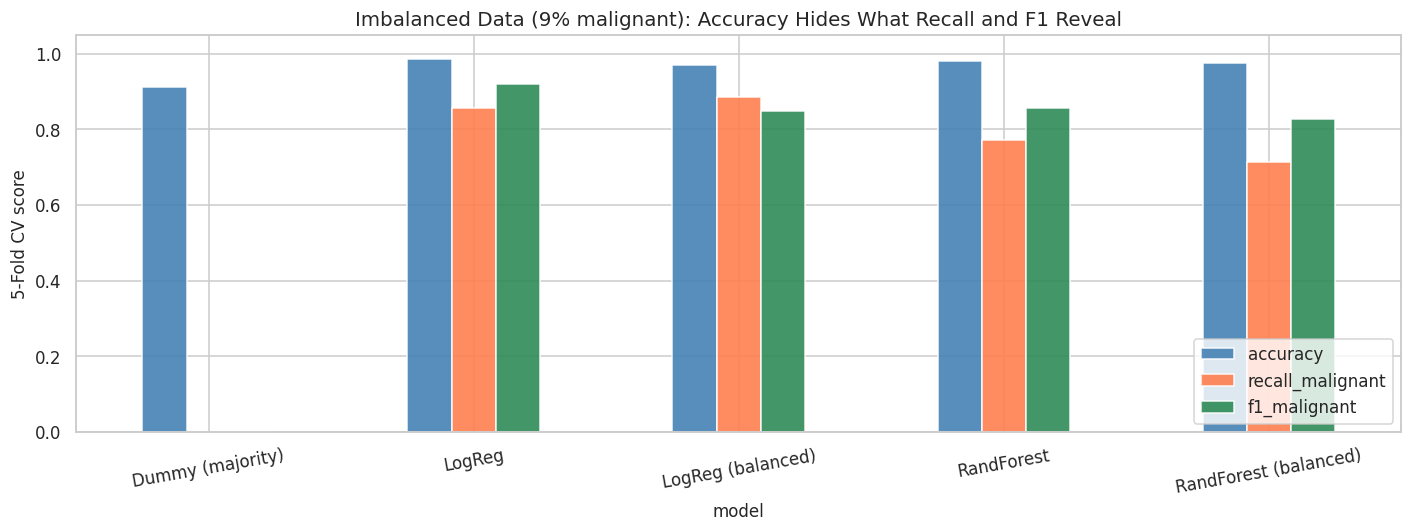

                       accuracy  recall_malignant  f1_malignant
model                                                          
Dummy (majority)          0.911             0.000         0.000
LogReg                    0.987             0.857         0.921
LogReg (balanced)         0.969             0.886         0.848
RandForest                0.980             0.771         0.856
RandForest (balanced)     0.974             0.714         0.827

The dummy model has ~91% accuracy and 0% recall. Always read accuracy next to recall and F1.
class_weight shifts the precision/recall balance but is not a guaranteed fix: compare the rows, do not assume.


In [ ]:
# ── 6.1  Build an imbalanced dataset and compare strategies ──────────
# Keep every benign sample but only 35 malignant ones.

mal_idx = np.where(y_bc == 0)[0]
ben_idx = np.where(y_bc == 1)[0]
keep    = np.concatenate([ben_idx, RNG.choice(mal_idx, size=35, replace=False)])

X_imb = X_bc.iloc[keep].reset_index(drop=True)
y_imb = y_bc.iloc[keep].reset_index(drop=True)
print(f"Imbalanced set: {len(y_imb)} samples, malignant = {(y_imb == 0).sum()} "
      f"({(y_imb == 0).mean() * 100:.1f}%)")

imb_models = {
    "Dummy (majority)":      DummyClassifier(strategy="most_frequent"),
    "LogReg":                Pipeline([("s", StandardScaler()), ("c", LogisticRegression(max_iter=5000))]),
    "LogReg (balanced)":     Pipeline([("s", StandardScaler()), ("c", LogisticRegression(max_iter=5000, class_weight="balanced"))]),
    "RandForest":            RandomForestClassifier(n_estimators=200, random_state=42),
    "RandForest (balanced)": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=42),
}

scoring = {
    "accuracy":         "accuracy",
    "recall_malignant": make_scorer(recall_score, pos_label=0),
    "f1_malignant":     make_scorer(f1_score,     pos_label=0),
}

imb_rows = []
for name, m in imb_models.items():
    r = cross_validate(m, X_imb, y_imb, cv=cv, scoring=scoring)
    imb_rows.append({"model": name,
                     "accuracy":         r["test_accuracy"].mean(),
                     "recall_malignant": r["test_recall_malignant"].mean(),
                     "f1_malignant":     r["test_f1_malignant"].mean()})
imb_df = pd.DataFrame(imb_rows).set_index("model")

fig, ax = plt.subplots(figsize=(13, 5))
imb_df.plot(kind="bar", ax=ax, edgecolor="white", alpha=0.9, color=["steelblue", "coral", "seagreen"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("5-Fold CV score")
ax.set_title("Imbalanced Data (9% malignant): Accuracy Hides What Recall and F1 Reveal")
ax.tick_params(axis="x", rotation=10)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(imb_df.round(3).to_string())
print("\nThe dummy model has ~91% accuracy and 0% recall. Always read accuracy next to recall and F1.")
print("class_weight shifts the precision/recall balance but is not a guaranteed fix: compare the rows, do not assume.")

---
## Part 7: The Full Classification Dashboard: Storytelling

A good classification report tells the audience four things: **can the model do the job, how does it compare, where does it fail, and what trade-off did we choose?**

**Storytelling checklist:**
1. **Comparison:** how do the candidate models rank under cross-validation?
2. **Discrimination:** how well does each rank positives above negatives (ROC)?
3. **Errors:** what exactly does the final model get wrong (confusion matrix)?
4. **Trade-off:** how does the threshold move precision and recall?

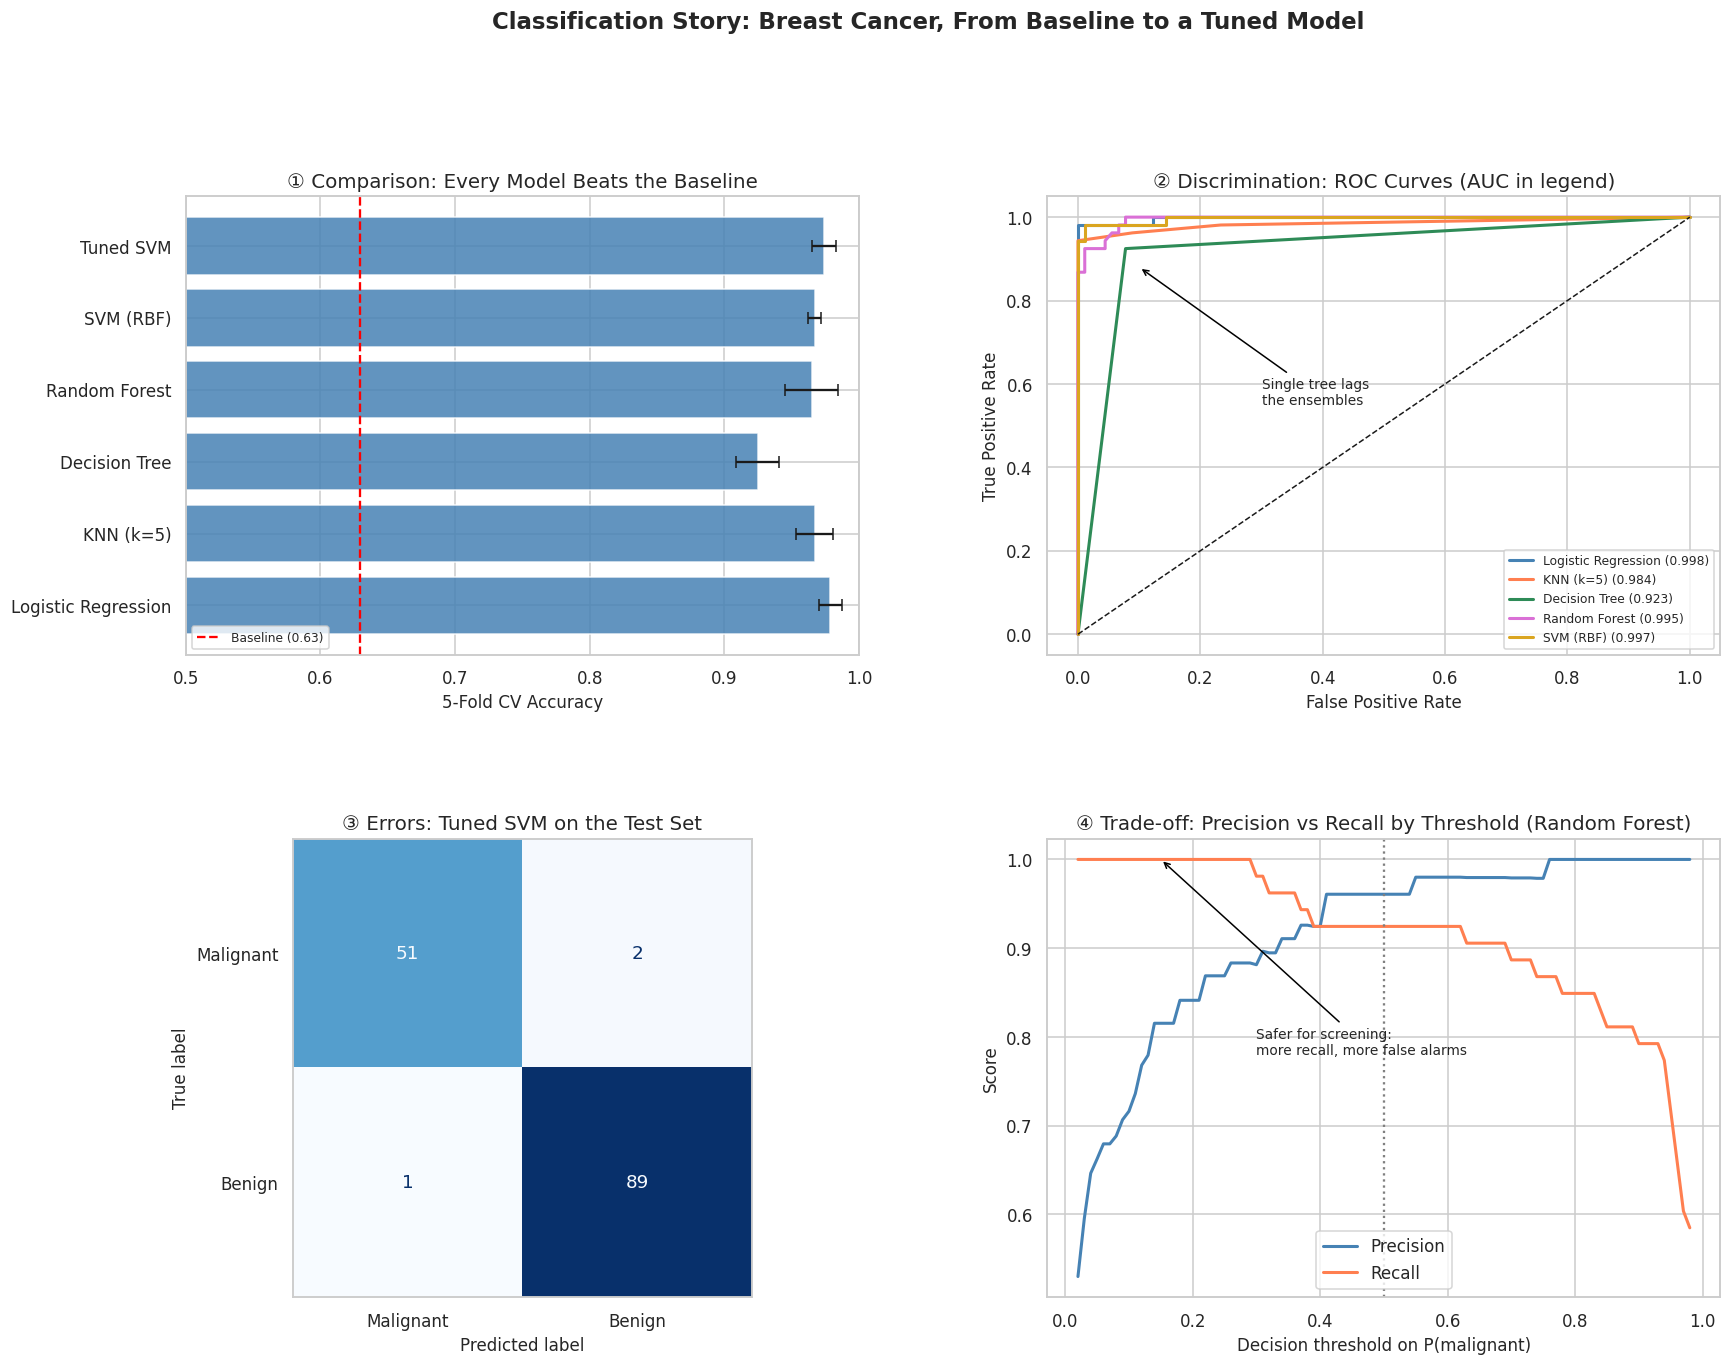

Dashboard saved as classification_dashboard.png


In [ ]:
# ── 7.1  The Classification Dashboard ────────────────────────────────

fig = plt.figure(figsize=(18, 13))
fig.suptitle("Classification Story: Breast Cancer, From Baseline to a Tuned Model",
             fontsize=15, fontweight="bold", y=1.01)

gs = gridspec.GridSpec(2, 2, hspace=0.40, wspace=0.28)

# ── Panel 1: model comparison (CV accuracy) ───────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
names = list(results_df.index) + ["Tuned SVM"]
cv_means = list(results_df["cv_acc"]) + [grid.best_score_]
cv_stds  = list(results_df["cv_std"]) + [scores.loc[grid.best_index_, "std_test_score"]]
base_acc = accuracy_score(y_test, dummy_pred)
bars = ax1.barh(names, cv_means, xerr=cv_stds, color="steelblue", edgecolor="white", alpha=0.85, capsize=4)
ax1.axvline(base_acc, color="red", linestyle="--", linewidth=1.5, label=f"Baseline ({base_acc:.2f})")
ax1.set_xlim(0.5, 1.0)
ax1.set_xlabel("5-Fold CV Accuracy")
ax1.set_title("① Comparison: Every Model Beats the Baseline")
ax1.legend(loc="lower left", fontsize=8)

# ── Panel 2: ROC curves ───────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
for (name, pipe), color in zip(models.items(), palette):
    p = pipe.predict_proba(X_test)[:, 0]
    fpr, tpr, _ = roc_curve(y_mal, p)
    ax2.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} ({roc_auc_score(y_mal, p):.3f})")
ax2.plot([0, 1], [0, 1], "k--", linewidth=1)
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.set_title("② Discrimination: ROC Curves (AUC in legend)")
ax2.legend(loc="lower right", fontsize=8)
ax2.annotate("Single tree lags\nthe ensembles", xy=(0.10, 0.88), xytext=(0.30, 0.55),
             fontsize=9, arrowprops=dict(arrowstyle="->", color="black"))

# ── Panel 3: confusion matrix of the tuned SVM ────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
ConfusionMatrixDisplay.from_predictions(
    y_test, tuned_svm.predict(X_test), display_labels=["Malignant", "Benign"],
    cmap="Blues", colorbar=False, ax=ax3)
ax3.grid(False)
ax3.set_title("③ Errors: Tuned SVM on the Test Set")

# ── Panel 4: threshold trade-off ──────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(thresholds, prec, color="steelblue", linewidth=2, label="Precision")
ax4.plot(thresholds, rec,  color="coral",     linewidth=2, label="Recall")
ax4.axvline(0.5, color="grey", linestyle=":", linewidth=1.5)
ax4.set_xlabel("Decision threshold on P(malignant)")
ax4.set_ylabel("Score")
ax4.set_title("④ Trade-off: Precision vs Recall by Threshold (Random Forest)")
ax4.legend(loc="lower center")
ax4.annotate("Safer for screening:\nmore recall, more false alarms", xy=(0.15, rec[13]),
             xytext=(0.30, 0.78), fontsize=9, arrowprops=dict(arrowstyle="->", color="black"))

plt.tight_layout()
plt.savefig("classification_dashboard.png", dpi=110, bbox_inches="tight")
plt.show()
print("Dashboard saved as classification_dashboard.png")

### Exercise 5: Final Challenge

Using the **Wine dataset** (`X_wine`, `y_wine`, 13 features, 3 classes), build your own **Classification Dashboard** that tells the full modelling story.

1. **Panel 1 (Comparison):** horizontal bar chart of 5-fold CV accuracy for at least four models, with the majority-class baseline as a dashed line.
2. **Panel 2 (Errors):** 3 × 3 confusion matrix of your best model on the test set.
3. **Panel 3 (Complexity):** validation curve (train vs CV) for one hyperparameter of your choice.
4. **Panel 4 (Signal):** Random Forest feature importances, top 8 features, horizontal bar chart.
5. Combine all four panels in a `2×2` `GridSpec` figure with a headline title.
6. Add **at least one annotation** on any panel highlighting the most important insight.
7. Write 3-4 sentences below the dashboard summarising:
   - Which model would you deploy and why?
   - Is there evidence of overfitting in any candidate?
   - Which features drive the classification?
   - Would accuracy alone have been enough to evaluate this problem? Why or why not?

```python
# Your code here
```

```
# Your answer here
```

---
## Summary

| Concept | What it solves | Key tools |
|---|---|---|
| **Stratified split** | Fair train/test with imbalanced classes | `train_test_split(stratify=y)` |
| **Baseline** | A floor every model must beat | `DummyClassifier` |
| **Logistic Regression / SVM / KNN** | Scale-sensitive classifiers | Put `StandardScaler` in the `Pipeline` |
| **Decision Tree / Random Forest** | Scale-free, non-linear, interpretable | `DecisionTreeClassifier`, `RandomForestClassifier` |
| **Confusion matrix** | See *which* errors the model makes | `confusion_matrix`, `ConfusionMatrixDisplay` |
| **Precision / Recall / F1** | Metrics that respect class roles | `classification_report` |
| **ROC-AUC** | Threshold-free ranking quality | `roc_curve`, `roc_auc_score` |
| **Validation curve** | Diagnose under/overfitting | `validation_curve` |
| **GridSearchCV** | Systematic hyperparameter tuning | `GridSearchCV`, `RandomizedSearchCV` |
| **Class weights** | Handle rare classes | `class_weight="balanced"` |

---
**The classification decision loop:**
1. Split first, stratified, and lock away the test set  
2. Fit a baseline so you know what "better" means  
3. Compare several models with cross-validation, scaling inside the pipeline  
4. Choose the metric that matches the **cost of errors**, not the default one  
5. Diagnose with validation curves, then tune with `GridSearchCV` on the training set  
6. Touch the test set once, report it honestly, and tune the **threshold** to the real-world trade-off